# Indian Election Data Analysis
## Lok Sabha Election 2024
**Data Analysis using Python, Pandas and Plotly**

In [2]:
#Step 1 – Jupyter Notebook file
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

print("Indian Election Data Analysis")
print("Libraries Imported Successfully!")

Indian Election Data Analysis
Libraries Imported Successfully!


In [3]:
# step 2 Load Election Dataset

df = pd.read_csv(
    "../dataset/eci_data_2024.csv",
    encoding="latin1"
)

print("Dataset Loaded Successfully!")

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

Dataset Loaded Successfully!
Total Rows: 8902
Total Columns: 9

Column Names:
['S.N', 'Candidate', 'Party', 'EVM Votes', 'Postal Votes', 'Total Votes', '% of Votes', 'State', 'Constituency']

First 5 Records:


,S.N,Candidate,Party,EVM Votes,Postal Votes,Total Votes,% of Votes,State,Constituency
0,1,BISHNU PADA RAY,Bharatiya Janata Party,102182,254,102436,50.58,Andaman & Nicobar Islands,Andaman & Nicobar Islands - 1
1,2,KULDEEP RAI SHARMA,Indian National Congress,77829,211,78040,38.54,Andaman & Nicobar Islands,Andaman & Nicobar Islands - 1
2,3,MANOJ PAUL,Andaman Nicobar Democratic Congress,8236,18,8254,4.08,Andaman & Nicobar Islands,Andaman & Nicobar Islands - 1
3,4,D AYYAPPAN,Communist Party of India (Marxist),6009,8,6017,2.97,Andaman & Nicobar Islands,Andaman & Nicobar Islands - 1
4,5,V.K. ABDUL AZIZ,Independent,2195,8,2203,1.09,Andaman & Nicobar Islands,Andaman & Nicobar Islands - 1


In [4]:
#step 3 - Dataset Overview

print("DATASET INFORMATION")

print("\n1. Dataset Shape:")
print(df.shape)

print("\n2. Dataset Information:")
df.info()

print("\n3. Statistical Summary:")
display(df.describe())

print("\n4. Dataset Memory Usage:")
print(df.memory_usage(deep=True).sum()/ 1024*2, "MB")

DATASET INFORMATION

1. Dataset Shape:
(8902, 9)

2. Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 8902 entries, 0 to 8901
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   S.N           8902 non-null   int64
 1   Candidate     8902 non-null   str  
 2   Party         8902 non-null   str  
 3   EVM Votes     8902 non-null   str  
 4   Postal Votes  8902 non-null   str  
 5   Total Votes   8902 non-null   str  
 6   % of Votes    8902 non-null   str  
 7   State         8902 non-null   str  
 8   Constituency  8902 non-null   str  
dtypes: int64(1), str(8)
memory usage: 626.1 KB

3. Statistical Summary:


,S.N
count,8902.000000
mean,10.818243
std,8.252271
min,1.000000
25%,5.000000
50%,9.000000
75%,15.000000
max,55.000000



4. Dataset Memory Usage:
8205.205078125 MB


In [5]:
#Cell 4 – Missing Values Analysis

print("MISSING VALUES ANALYSIS")

missing_values = df.isnull().sum()

print("\nMissing Values in Each Column:")
display(missing_values)

print("\nTotal Missing Values:")
print(missing_values.sum())

print("\nMissing Values Percentage:")
missing_percentage = (df.isnull().sum() / len(df)) * 100

display(missing_percentage.round(2))

MISSING VALUES ANALYSIS

Missing Values in Each Column:


S.N             0
Candidate       0
Party           0
EVM Votes       0
Postal Votes    0
Total Votes     0
% of Votes      0
State           0
Constituency    0
dtype: int64


Total Missing Values:
0

Missing Values Percentage:


S.N             0.0
Candidate       0.0
Party           0.0
EVM Votes       0.0
Postal Votes    0.0
Total Votes     0.0
% of Votes      0.0
State           0.0
Constituency    0.0
dtype: float64

In [6]:
#Cell 5: # Duplicate Records Analysis

print("DUPLICATE RECORDS ANALYSIS")

# count duplicate rows
duplicate_count = df.duplicated().sum()
print("\nTotal Duplicate Records:", duplicate_count)

# calculate duplicate percentage
duplicate_percentage = (duplicate_count / len(df)) * 100
print("Duplicate Percentage:", round(duplicate_percentage, 2), "%")

#Display duplicate records
print("\nDuplicate Record:")
display(df[df.duplicated()])

DUPLICATE RECORDS ANALYSIS

Total Duplicate Records: 0
Duplicate Percentage: 0.0 %

Duplicate Record:


,S.N,Candidate,Party,EVM Votes,Postal Votes,Total Votes,% of Votes,State,Constituency


In [7]:
#Cell 6: Data Type Conversion

numeric_columns = [
    "EVM Votes",
    "Postal Votes",
    "Total Votes",
    "% of Votes"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("\nAFTER CONVERSION:")
print(df.dtypes)

print("\nMissing Values After Conversion:")
print(df[numeric_columns].isnull().sum())


AFTER CONVERSION:
S.N               int64
Candidate           str
Party               str
EVM Votes       float64
Postal Votes    float64
Total Votes     float64
% of Votes      float64
State               str
Constituency        str
dtype: object

Missing Values After Conversion:
EVM Votes         1
Postal Votes    578
Total Votes       1
% of Votes        1
dtype: int64


In [8]:
# Step 7: Missing Values Analysis

print("MISSING VALUES DETAILS")

# check rows having missing values
missing_rows = df[df.isnull().any(axis=1)]

print("\nTotal Rows Having Missing Values:")
print(len(missing_rows))

print("\nMissing Values by Column:")
display(df.isnull().sum())

print("\nFirst 10 Records with Missing Values:")
display(missing_rows.head(10))

MISSING VALUES DETAILS

Total Rows Having Missing Values:
578

Missing Values by Column:


S.N               0
Candidate         0
Party             0
EVM Votes         1
Postal Votes    578
Total Votes       1
% of Votes        1
State             0
Constituency      0
dtype: int64


First 10 Records with Missing Values:


,S.N,Candidate,Party,EVM Votes,Postal Votes,Total Votes,% of Votes,State,Constituency
11,12,ANAND RAMNATH ARLEKAR,Independent,342.0,NaN,342.0,0.17,Andaman & Nicobar Islands,Andaman & Nicobar Islands - 1
143,13,VISHNU REDDY LANKIREDDY,Bengaluru Nava Nirmana Party,461.0,NaN,461.0,0.03,Andhra Pradesh,Guntur - 13
150,20,ASHOK ANAND GALI,Independent,335.0,NaN,335.0,0.02,Andhra Pradesh,Guntur - 13
156,26,VANKAYALAPATI VENKATA SIVA RAMANJANEYULU,Independent,268.0,NaN,268.0,0.02,Andhra Pradesh,Guntur - 13
159,29,SRIKRISHNA AKKISETTI,Independent,179.0,NaN,179.0,0.01,Andhra Pradesh,Guntur - 13
160,30,MADAVARAPU NAGA RAJU,Independent,172.0,NaN,172.0,0.01,Andhra Pradesh,Guntur - 13
203,13,BODDETI APPARAO,Independent,1687.0,NaN,1687.0,0.13,Andhra Pradesh,Kakinada - 6
249,7,KOMMUSANI PEDDA KAMBAGIRI SWAMY,Independent,4633.0,NaN,4633.0,0.33,Andhra Pradesh,Nandyal - 17
258,16,VIJAYA BHASKAR REDDYPOGU,Independent,641.0,NaN,641.0,0.05,Andhra Pradesh,Nandyal - 17
263,21,B C RAMANADHA AREDDY,Independent,472.0,NaN,472.0,0.03,Andhra Pradesh,Nandyal - 17


In [9]:
# Step 8: Verify Missing Postal Votes

postal_missing = df[df["Postal Votes"].isnull()]
print("Total Missing Postal Votes:", len(postal_missing))
print("\nCheck EVM Votes and Total Votes:")
display(
    postal_missing[
        ["Candidate", "EVM Votes", "Postal Votes", "Total Votes"]
    ].head(15)
)

print("\nCheck EVM Votes == Total Votes:")
print(
    (postal_missing["EVM Votes"] == postal_missing["Total Votes"]).value_counts()
)

Total Missing Postal Votes: 578

Check EVM Votes and Total Votes:


,Candidate,EVM Votes,Postal Votes,Total Votes
11,ANAND RAMNATH ARLEKAR,342.0,NaN,342.0
143,VISHNU REDDY LANKIREDDY,461.0,NaN,461.0
150,ASHOK ANAND GALI,335.0,NaN,335.0
156,VANKAYALAPATI VENKATA SIVA RAMANJANEYULU,268.0,NaN,268.0
159,SRIKRISHNA AKKISETTI,179.0,NaN,179.0
160,MADAVARAPU NAGA RAJU,172.0,NaN,172.0
203,BODDETI APPARAO,1687.0,NaN,1687.0
249,KOMMUSANI PEDDA KAMBAGIRI SWAMY,4633.0,NaN,4633.0
258,VIJAYA BHASKAR REDDYPOGU,641.0,NaN,641.0
263,B C RAMANADHA AREDDY,472.0,NaN,472.0



Check EVM Votes == Total Votes:
True     577
False      1
Name: count, dtype: int64


In [10]:
# Step 9: Find Mismatched Record

postal_missing = df[df["Postal Votes"].isnull()]

mismatched_rows = postal_missing[
    postal_missing["EVM Votes"] != postal_missing["Total Votes"]
]

print("Total Mismatched Records:", len(mismatched_rows))

display(
    mismatched_rows[
        [
            "Candidate",
            "Party",
            "EVM Votes",
            "Postal Votes",
            "Total Votes",
            "% of Votes",
            "State",
            "Constituency"
        ]
    ]
)

Total Mismatched Records: 1


,Candidate,Party,EVM Votes,Postal Votes,Total Votes,% of Votes,State,Constituency
1737,MUKESHKUMAR CHANDRAKAANT DALAL ( Uncontested ),Bharatiya Janata Party,NaN,NaN,NaN,NaN,Gujarat,Surat - 24


In [11]:
# Step 10: Handle Missing Values

# Fill 577 missing Postal Votes with 0
df.loc[
    df["Postal Votes"].isnull() &
    df["EVM Votes"].notnull() &
    df["Total Votes"].notnull() &
    (df["EVM Votes"] == df["Total Votes"]),
    "Postal Votes"
] = 0

# Fill uncontested candidate's missing vote values with 0
df.loc[
    df["Candidate"].str.contains("Uncontested", case=False, na=False),
    ["EVM Votes", "Postal Votes", "Total Votes", "% of Votes"]
] = 0

print("Missing Values After Handling:")
display(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values After Handling:


S.N             0
Candidate       0
Party           0
EVM Votes       0
Postal Votes    0
Total Votes     0
% of Votes      0
State           0
Constituency    0
dtype: int64


Total Missing Values: 0


In [12]:
# Step 11: Data Validation

# Check vote calculation
df["Calculated Total Votes"] = df["EVM Votes"] + df["Postal Votes"]

# Find incorrect records
invalid_records = df[
    df["Calculated Total Votes"] != df["Total Votes"]
]

print("Total Records:", len(df))
print("Invalid Vote Records:", len(invalid_records))

print("\nFirst 10 Invalid Records:")
display(invalid_records.head(10))

Total Records: 8902
Invalid Vote Records: 0

First 10 Invalid Records:


,S.N,Candidate,Party,EVM Votes,Postal Votes,Total Votes,% of Votes,State,Constituency,Calculated Total Votes


In [13]:
# Step 12: Feature Engineering

# Create Vote Category
df["Vote Category"] = pd.cut(
    df["Total Votes"],
    bins=[-1, 1000, 10000, float("inf")],
    labels=["Low Votes", "Medium Votes", "High Votes"]
)

# Create Vote Share Category
df["Vote Share Category"] = pd.cut(
    df["% of Votes"],
    bins=[-0.01, 1, 10, 50, 100],
    labels=["Below 1%", "1% to 10%", "10% to 50%", "Above 50%"]
)

print("New Columns Created Successfully!")

print("\nUpdated Dataset Shape:")
print(df.shape)

print("\nNew Columns:")
display(df[["Candidate", "Total Votes", "% of Votes",
            "Vote Category", "Vote Share Category"]].head(10))

New Columns Created Successfully!

Updated Dataset Shape:
(8902, 12)

New Columns:


,Candidate,Total Votes,% of Votes,Vote Category,Vote Share Category
0,BISHNU PADA RAY,102436.0,50.58,High Votes,Above 50%
1,KULDEEP RAI SHARMA,78040.0,38.54,High Votes,10% to 50%
2,MANOJ PAUL,8254.0,4.08,Medium Votes,1% to 10%
3,D AYYAPPAN,6017.0,2.97,Medium Votes,1% to 10%
4,V.K. ABDUL AZIZ,2203.0,1.09,Medium Votes,1% to 10%
5,K J B SELVARAJ,914.0,0.45,Low Votes,Below 1%
6,DR ARUN KUMAR MALLIK,719.0,0.36,Low Votes,Below 1%
7,RINKU MALA MONDAL,542.0,0.27,Low Votes,Below 1%
8,K VENKAT RAM BABU,507.0,0.25,Low Votes,Below 1%
9,USHA KUMARI,380.0,0.19,Low Votes,Below 1%


In [14]:
# Step 13: Basic Election Analysis

print("INDIAN LOK SABHA ELECTION 2024 - BASIC ANALYSIS")

total_candidates = df["Candidate"].nunique()
total_parties = df["Party"].nunique()
total_states = df["State"].nunique()
total_constituencies = df["Constituency"].nunique()

print("\nTotal Candidates:", total_candidates)
print("Total political Parties:", total_parties)
print("Total States:", total_states)
print("Total Constituencies:", total_constituencies)

print("\nTotal Votes polled:", int(df["Total Votes"].sum()))

INDIAN LOK SABHA ELECTION 2024 - BASIC ANALYSIS

Total Candidates: 8099
Total political Parties: 746
Total States: 36
Total Constituencies: 543

Total Votes polled: 645363445


In [15]:
# Step 14: Party-wise Analysis

party_analysis = df.groupby('Party').agg(
    Total_Votes=('Total Votes', "sum"),
    Total_Candidates=('Candidate', "count")
).reset_index()

# Sort by total votes
party_analysis = party_analysis.sort_values(
    by="Total_Votes",
    ascending=False
)

print('TOP 10 POLICTICAL PARTIES BY TOTAL VOTES')
display(party_analysis.head(10))


TOP 10 POLICTICAL PARTIES BY TOTAL VOTES


,Party,Total_Votes,Total_Candidates
158,Bharatiya Janata Party,235973935.0,441
289,Indian National Congress,136759064.0,328
617,Samajwadi Party,29549381.0,71
69,All India Trinamool Congress,28213393.0,48
282,Independent,17844442.0,3920
744,Yuvajana Sramika Rythu Congress Party,13316039.0,25
121,Bahujan Samaj Party,13153818.0,488
698,Telugu Desam,12775270.0,17
250,Dravida Munnetra Kazhagam,11754710.0,22
227,Communist Party of India (Marxist),11342553.0,52


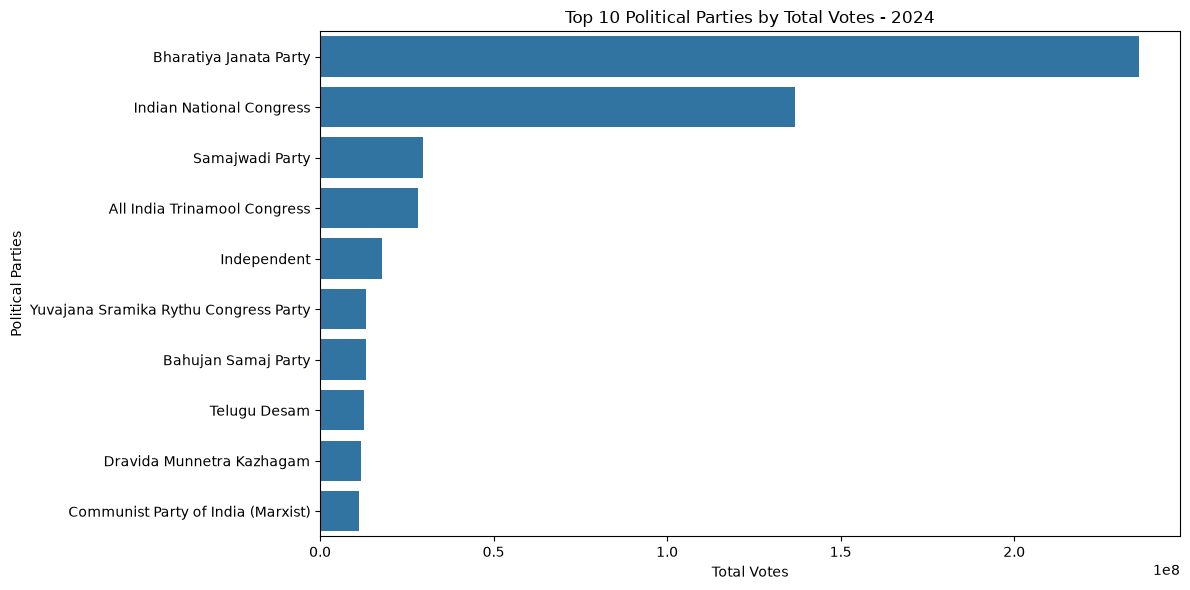

In [16]:
# Step 15: Top 10 Parties Bar Chart

top_10_parties = party_analysis.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_parties,
    x="Total_Votes",
    y="Party"
)

plt.title("Top 10 Political Parties by Total Votes - 2024")
plt.xlabel("Total Votes")
plt.ylabel("Political Parties")

plt.tight_layout()
plt.show()

In [17]:
# Step 16: State-wise Election Analysis

state_analysis = df.groupby("State").agg(
    Total_Votes=('Total Votes', "sum"),
    Total_Constituencies=("Constituency", "unique"),
    Total_Candidates=("Candidate", "count")
).reset_index()

# Sort by total votes
state_analysis = state_analysis.sort_values(
    by="Total_Votes",
    ascending=False
)

print("TOP 10 STATES BY TOTAL VOTES")
display(state_analysis.head(10))

TOP 10 STATES BY TOTAL VOTES


,State,Total_Votes,Total_Constituencies,Total_Candidates
33,Uttar Pradesh,87911642.0,"[Agra - 18, Akbarpur - 44, Aligarh - 15, Allah...",931
35,West Bengal,60483687.0,"[Alipurduars - 2, Arambagh - 29, Asansol - 40,...",549
19,Maharashtra,57179133.0,"[Ahmednagar - 37, Akola - 6, Amravati - 7, Aur...",1169
30,Tamil Nadu,43674048.0,"[ARAKKONAM - 7, ARANI - 12, CHENNAI CENTRAL - ...",989
4,Bihar,43448949.0,"[Araria - 9, Arrah - 32, Aurangabad - 37, Bank...",537
14,Karnataka,38793617.0,"[Bagalkot - 3, Bangalore central - 25, Bangalo...",502
18,Madhya Pradesh,37940251.0,"[BALAGHAT - 15, BETUL - 29, BHIND - 2, BHOPAL ...",398
1,Andhra Pradesh,33729342.0,"[Amalapuram (SC) - 7, Anakapalle - 5, Ananthap...",479
28,Rajasthan,33164877.0,"[AJMER - 13, ALWAR - 8, BANSWARA - 20, BARMER ...",291
9,Gujarat,29115599.0,"[Ahmedabad East - 7, Ahmedabad West - 8, Amrel...",291


In [18]:
# Step 17: Correct State-wise Analysis

state_analysis = df.groupby("State").agg(
    Total_Votes=("Total Votes", "sum"),
    Total_Constituencies=("Constituency", "nunique"),
    Total_Candidates=("Candidate", "count")
).reset_index()

state_analysis = state_analysis.sort_values(
    by="Total_Votes",
    ascending=False
)

print("TOP 10 STATES BY TOTAL VOTES")

display(state_analysis.head(10))

TOP 10 STATES BY TOTAL VOTES


,State,Total_Votes,Total_Constituencies,Total_Candidates
33,Uttar Pradesh,87911642.0,80,931
35,West Bengal,60483687.0,42,549
19,Maharashtra,57179133.0,48,1169
30,Tamil Nadu,43674048.0,39,989
4,Bihar,43448949.0,40,537
14,Karnataka,38793617.0,28,502
18,Madhya Pradesh,37940251.0,29,398
1,Andhra Pradesh,33729342.0,25,479
28,Rajasthan,33164877.0,25,291
9,Gujarat,29115599.0,26,291


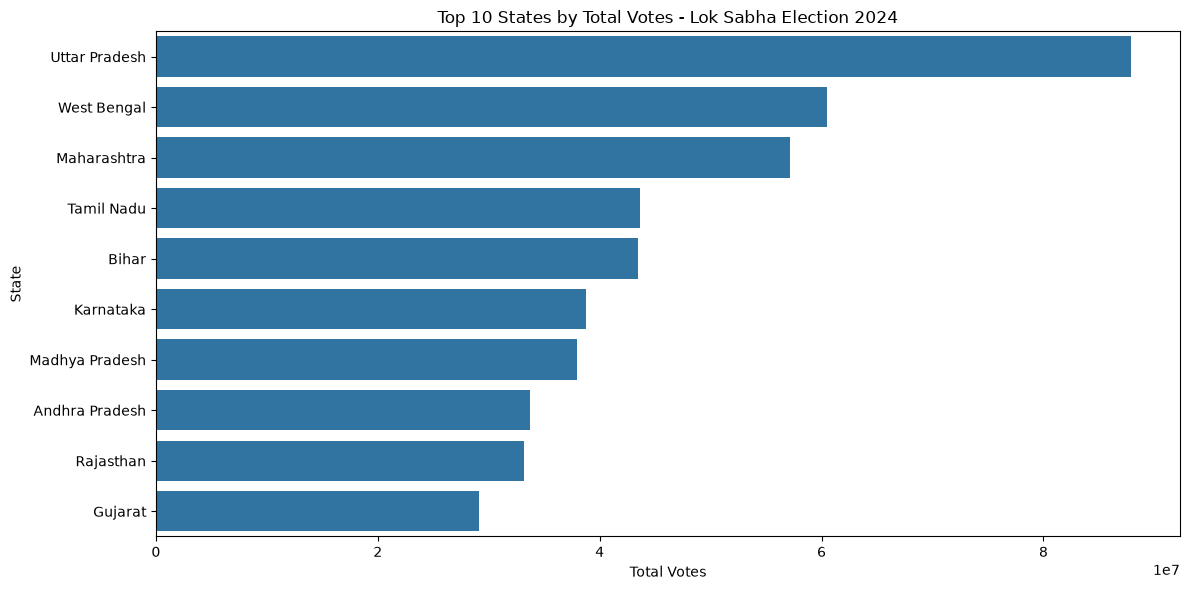

In [19]:
# Step 18: State-wise Bar Chart

top_10_states = state_analysis.head(10)
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_states,
    x="Total_Votes",
    y="State"
)

plt.title("Top 10 States by Total Votes - Lok Sabha Election 2024")
plt.xlabel('Total Votes')
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [20]:
# Step 19: Candidate-wise Analysis

candidate_analysis = df.sort_values(
    by="Total Votes",
    ascending=False
)

print("TOP 10 CANDIDATES BY TOTAL VOTES")

display(
    candidate_analysis[
        ["Candidate", "Party", "State",
         "Constituency", "Total Votes", "% of Votes"]
    ].head(10)
)

TOP 10 CANDIDATES BY TOTAL VOTES


,Candidate,Party,State,Constituency,Total Votes,% of Votes
535,RAKIBUL HUSSAIN,Indian National Congress,Assam,Dhubri - 2,1471885.0,59.99
3289,SHANKAR LALWANI,Bharatiya Janata Party,Madhya Pradesh,INDORE - 26,1226751.0,78.54
3522,SHIVRAJ SINGH CHOUHAN,Bharatiya Janata Party,Madhya Pradesh,VIDISHA - 18,1116460.0,76.70
2483,DR C N MANJUNATH,Bharatiya Janata Party,Karnataka,Bangalore Rural - 23,1079002.0,56.21
1387,BRIJMOHAN AGRAWAL,Bharatiya Janata Party,Chhattisgarh,RAIPUR - 8,1050351.0,66.19
8565,ABHISHEK BANERJEE,All India Trinamool Congress,West Bengal,Diamond harbour - 21,1048230.0,68.48
1664,C R PATIL,Bharatiya Janata Party,Gujarat,Navsari - 25,1031065.0,77.05
1590,AMIT SHAH,Bharatiya Janata Party,Gujarat,Gandhinagar - 6,1010972.0,76.48
7049,EATALA RAJENDER,Bharatiya Janata Party,Telangana,Malkajgiri - 7,991042.0,51.25
2461,SHOBHA KARANDLAJE,Bharatiya Janata Party,Karnataka,Bangalore North - 24,986049.0,56.27


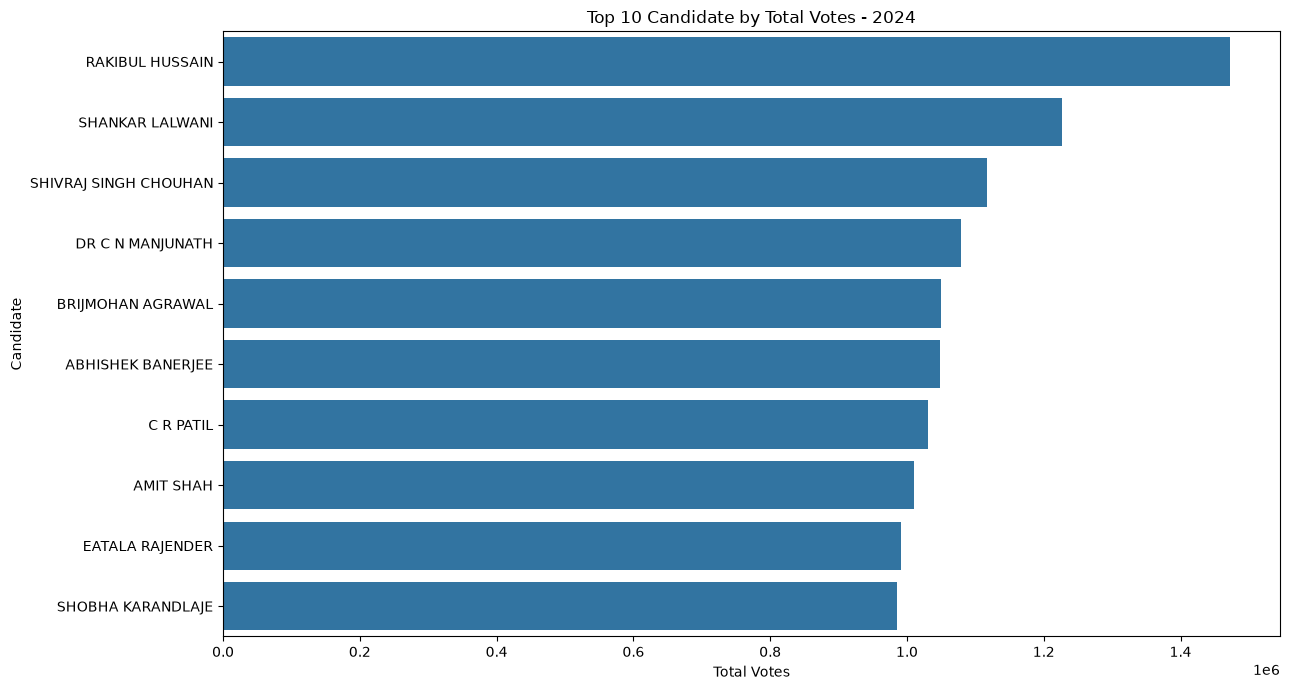

In [21]:
# Step 20: Top 10 Candidates Bar Chart

top_10_candidates = candidate_analysis.head(10)
plt.figure(figsize=(13, 7))

sns.barplot(
    data=top_10_candidates,
    x="Total Votes",
    y="Candidate"
)

plt.title("Top 10 Candidate by Total Votes - 2024")
plt.xlabel("Total Votes")
plt.ylabel("Candidate")

plt.tight_layout()
plt.show()

In [22]:
# Step 21: Vote Category Analysis

vote_category_analysis = df["Vote Category"].value_counts()

print("CANDIDATES BY VOTE CATEGORY")

display(vote_category_analysis)

print("\nPercentage Distribution:")

display(
    (df["Vote Category"].value_counts(normalize=True) * 100).round(2)
)

CANDIDATES BY VOTE CATEGORY


Vote Category
Medium Votes    4686
High Votes      2199
Low Votes       2017
Name: count, dtype: int64


Percentage Distribution:


Vote Category
Medium Votes    52.64
High Votes      24.70
Low Votes       22.66
Name: proportion, dtype: float64

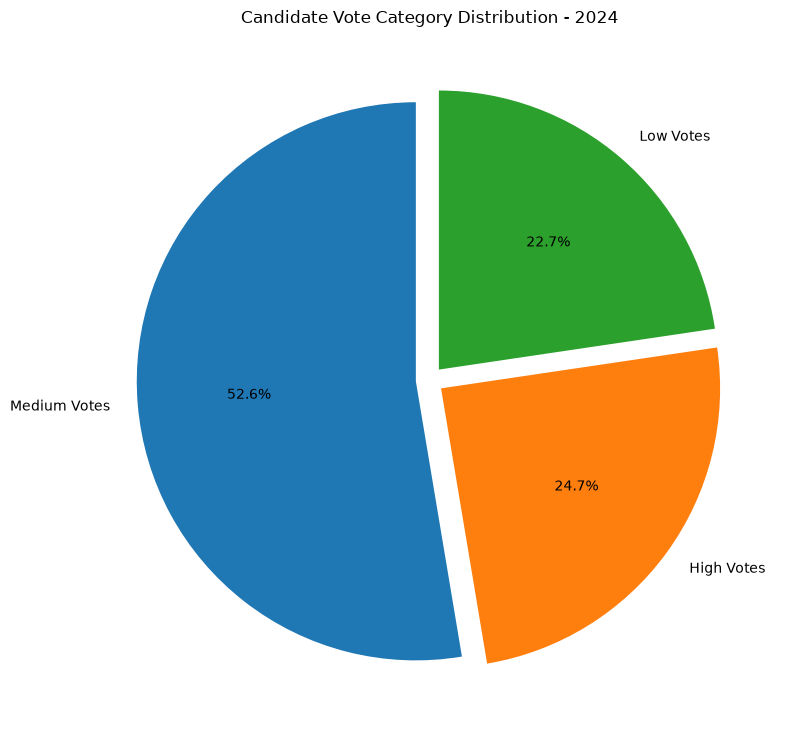

In [23]:

# Step 22: Vote Category Pie Chart

plt.figure(figsize=(8, 8))

vote_category_analysis.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    explode=(0.05, 0.05, 0.05)
)

plt.title("Candidate Vote Category Distribution - 2024")
plt.ylabel("")

plt.tight_layout()
plt.show()


In [24]:
# step 23: Vote Share Analysis

vote_share_analysis = df["Vote Share Category"].value_counts()

print("VOTE SHARE CATEGORY ANALYSIS")
print(vote_share_analysis)

VOTE SHARE CATEGORY ANALYSIS
Vote Share Category
Below 1%      6870
10% to 50%    1011
1% to 10%      766
Above 50%      255
Name: count, dtype: int64


In [25]:
# Step 24: Vote Share Percentage Distribution

vote_share_percentage = (
    df["Vote Share Category"]
    .value_counts(normalize=True) * 100
)

print("VOTE SHARE PERCENTAGE DISTRIBUTION")
print(vote_share_percentage.round(2))

VOTE SHARE PERCENTAGE DISTRIBUTION
Vote Share Category
Below 1%      77.17
10% to 50%    11.36
1% to 10%      8.60
Above 50%      2.86
Name: proportion, dtype: float64


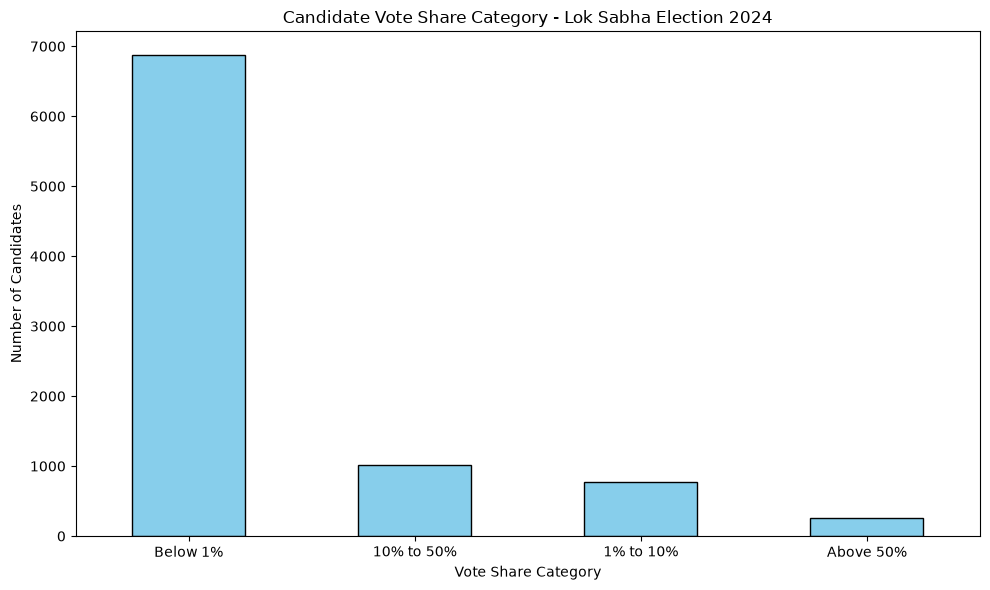

In [26]:
# Step 25: Vote Share Category Bar Chart

plt.figure(figsize=(10, 6))

vote_share_analysis.plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("Candidate Vote Share Category - Lok Sabha Election 2024")
plt.xlabel('Vote Share Category')
plt.ylabel("Number of Candidates")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [27]:
# Step 26: Top 10 Candidates Analysis

top_10_candidates = df.sort_values(
    by="Total Votes",
    ascending=False
).head(10)

print("TOP 10 CANDIDATES BY TOTAL VOTES")

display(
    top_10_candidates[
        ["Candidate", "Party", "State", "Constituency", "Total Votes"]
    ]
)

TOP 10 CANDIDATES BY TOTAL VOTES


,Candidate,Party,State,Constituency,Total Votes
535,RAKIBUL HUSSAIN,Indian National Congress,Assam,Dhubri - 2,1471885.0
3289,SHANKAR LALWANI,Bharatiya Janata Party,Madhya Pradesh,INDORE - 26,1226751.0
3522,SHIVRAJ SINGH CHOUHAN,Bharatiya Janata Party,Madhya Pradesh,VIDISHA - 18,1116460.0
2483,DR C N MANJUNATH,Bharatiya Janata Party,Karnataka,Bangalore Rural - 23,1079002.0
1387,BRIJMOHAN AGRAWAL,Bharatiya Janata Party,Chhattisgarh,RAIPUR - 8,1050351.0
8565,ABHISHEK BANERJEE,All India Trinamool Congress,West Bengal,Diamond harbour - 21,1048230.0
1664,C R PATIL,Bharatiya Janata Party,Gujarat,Navsari - 25,1031065.0
1590,AMIT SHAH,Bharatiya Janata Party,Gujarat,Gandhinagar - 6,1010972.0
7049,EATALA RAJENDER,Bharatiya Janata Party,Telangana,Malkajgiri - 7,991042.0
2461,SHOBHA KARANDLAJE,Bharatiya Janata Party,Karnataka,Bangalore North - 24,986049.0


In [28]:
# Step 27: Top 10 Political Parties Analysis

top_10_parties = (
    df.groupby("Party")["Total Votes"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("TOP 10 POLITICAL PARTIES BY TOTAL VOTES")
print(top_10_parties)

TOP 10 POLITICAL PARTIES BY TOTAL VOTES
Party
Bharatiya Janata Party                   235973935.0
Indian National Congress                 136759064.0
Samajwadi Party                           29549381.0
All India Trinamool Congress              28213393.0
Independent                               17844442.0
Yuvajana Sramika Rythu Congress Party     13316039.0
Bahujan Samaj Party                       13153818.0
Telugu Desam                              12775270.0
Dravida Munnetra Kazhagam                 11754710.0
Communist Party of India (Marxist)        11342553.0
Name: Total Votes, dtype: float64


In [29]:
# Step 28: State-wise Election Analysis

state_wise_analysis = (
    df.groupby("State")["Total Votes"]
    .sum()
    .sort_values(ascending=False)
)

print("STATE-WISE TOTAL VOTES ANALYSIS")
print(state_wise_analysis)


STATE-WISE TOTAL VOTES ANALYSIS
State
Uttar Pradesh                           87911642.0
West Bengal                             60483687.0
Maharashtra                             57179133.0
Tamil Nadu                              43674048.0
Bihar                                   43448949.0
Karnataka                               38793617.0
Madhya Pradesh                          37940251.0
Andhra Pradesh                          33729342.0
Rajasthan                               33164877.0
Gujarat                                 29115599.0
Odisha                                  25129026.0
Telangana                               22008373.0
Assam                                   20059870.0
Kerala                                  19980436.0
Jharkhand                               17241982.0
Chhattisgarh                            15061348.0
Punjab                                  13530923.0
Haryana                                 13055572.0
NCT OF Delhi                             893

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 [Text(0, 0, 'Uttar Pradesh'),
  Text(1, 0, 'West Bengal'),
  Text(2, 0, 'Maharashtra'),
  Text(3, 0, 'Tamil Nadu'),
  Text(4, 0, 'Bihar'),
  Text(5, 0, 'Karnataka'),
  Text(6, 0, 'Madhya Pradesh'),
  Text(7, 0, 'Andhra Pradesh'),
  Text(8, 0, 'Rajasthan'),
  Text(9, 0, 'Gujarat')])

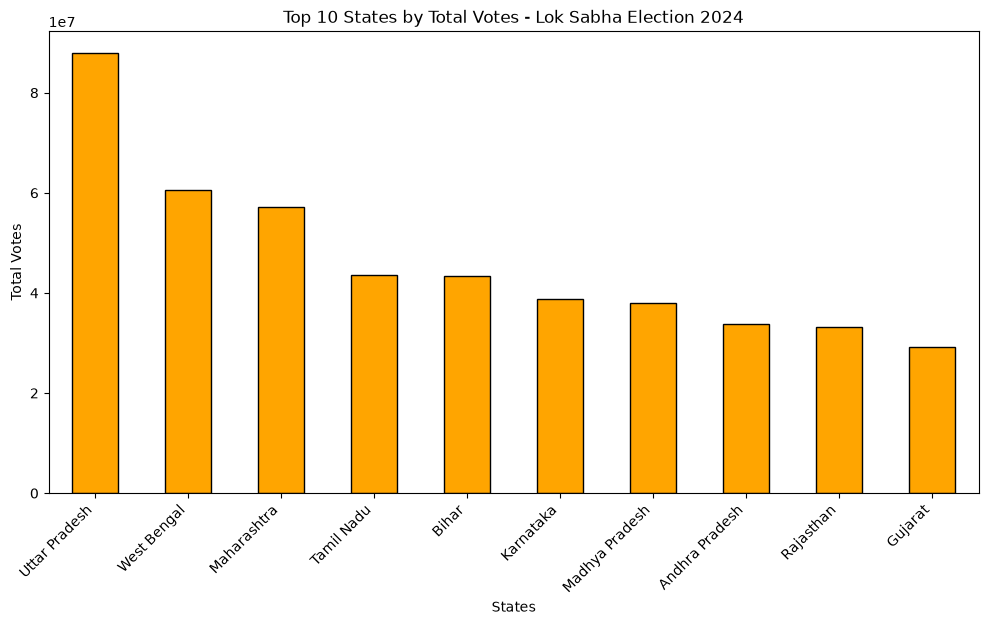

In [30]:
# Step 29: Top 10 States by Total Votes

plt.figure(figsize=(12, 6))

state_wise_analysis.head(10).plot(
    kind="bar",
    color="orange",
    edgecolor="black"
)
plt.title("Top 10 States by Total Votes - Lok Sabha Election 2024")
plt.xlabel("States")
plt.ylabel("Total Votes")
plt.xticks(rotation=45, ha="right")

In [31]:

# Step 30: Final Project Insights & Conclusion

print("=" * 60)
print("INDIAN LOK SABHA ELECTION 2024 - FINAL ANALYSIS REPORT")
print("=" * 60)

print("\n1. TOTAL CANDIDATES:", len(df))

print("\n2. TOTAL POLITICAL PARTIES:", df["Party"].nunique())

print("\n3. TOTAL STATES:", df["State"].nunique())

print("\n4. TOTAL CONSTITUENCIES:", df["Constituency"].nunique())

print("\n5. TOTAL VOTES:", f"{df['Total Votes'].sum():,.0f}")

print("\n6. TOP POLITICAL PARTY:")
print(top_10_parties.head(1))

print("\n7. TOP CANDIDATE:")
print(top_10_candidates[
    ["Candidate", "Party", "Total Votes"]
].head(1))

print("\n8. TOP STATE:")
print(state_wise_analysis.head(1))

print("\n" + "=" * 60)
print("PROJECT ANALYSIS COMPLETED SUCCESSFULLY!")
print("=" * 60)


INDIAN LOK SABHA ELECTION 2024 - FINAL ANALYSIS REPORT

1. TOTAL CANDIDATES: 8902

2. TOTAL POLITICAL PARTIES: 746

3. TOTAL STATES: 36

4. TOTAL CONSTITUENCIES: 543

5. TOTAL VOTES: 645,363,445

6. TOP POLITICAL PARTY:
Party
Bharatiya Janata Party    235973935.0
Name: Total Votes, dtype: float64

7. TOP CANDIDATE:
           Candidate                     Party  Total Votes
535  RAKIBUL HUSSAIN  Indian National Congress    1471885.0

8. TOP STATE:
State
Uttar Pradesh    87911642.0
Name: Total Votes, dtype: float64

PROJECT ANALYSIS COMPLETED SUCCESSFULLY!
